# Trap vs. Boom Bap: classificação de letras de rap brasileiro

**É possível distinguir trap e boom bap brasileiros só pela letra?** Este notebook responde com modelos clássicos de aprendizado de máquina, comparando representações de texto (estatísticas simples, TF-IDF e embeddings de um modelo de linguagem) sob uma avaliação rigorosa: o modelo é sempre testado em **artistas que ele nunca viu**.

| | |
|---|---|
| **Dados** | 710 letras de 58 artistas (359 de trap, 351 de boom bap), coletadas da API pública do [LRCLIB](https://lrclib.net) |
| **Rótulo** | gênero atribuído ao artista |
| **Modelos** | regressão logística sobre 5 representações, mais um baseline |
| **Validação** | `StratifiedGroupKFold` por artista; teste final com 11 artistas inéditos |
| **Resultado** | TF-IDF da letra: **91,9% ± 4,1** na validação cruzada e **93,6%** no teste |

**Principais conclusões**
- Vocabulário e forma (ad-libs, gírias, inglês, conectivos) separam os gêneros melhor que o significado: o TF-IDF supera os embeddings do Qwen3.
- Quatro estatísticas simples (tamanho da letra e uso de inglês) já chegam a 73,5% na validação cruzada.
- Limpar os dados (remover homônimos) rendeu mais que trocar de modelo.

**Sumário**
1. Configuração
2. Coleta de dados
3. Análise exploratória
4. Tratamento de dados
5. Separação de treino e teste
6. Modelos
7. Avaliação
8. Análise de erros
9. Conclusão
10. Classificando uma música nova

**Como executar** (Python 3.12+):

```bash
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
```

O repositório inclui `dataset.csv` e `embeddings.npz`, então o notebook roda de ponta a ponta sem coletar letras nem calcular embeddings (cerca de 10 minutos em GPU). Para refazer tudo do zero, basta apagar os dois arquivos. A seção 10 consulta o LRCLIB e precisa de internet.

## 1. Configuração

Bibliotecas e a paleta usada em todos os gráficos.

In [1]:
import functools
import hashlib
import os
import re
import ssl
import time
import unicodedata
import warnings
from collections import Counter

# barras de progresso do tqdm sem ipywidgets: aviso irrelevante aqui
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import torch
from langdetect import DetectorFactory, LangDetectException, detect
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from requests.adapters import HTTPAdapter
from sentence_transformers import SentenceTransformer
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, adjusted_rand_score, classification_report,
                             f1_score, silhouette_score)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from stop_words import get_stop_words
from wordfreq import zipf_frequency

CORES = {"trap": "#2a78d6", "boombap": "#eb6834"}  # paleta segura para daltonismo

## 2. Coleta de dados

As letras vêm da API pública do [LRCLIB](https://lrclib.net). Cada gênero tem uma lista de artistas representativos; a coleta busca um artista por vez e para ao atingir `ALVO` (400) letras por gênero. **O rótulo (`genero`) é herdado do artista.**

Regras:
- no máximo `MAX_POR_ARTISTA` (20) músicas por artista, para que poucos artistas não dominem a base;
- só entram resultados em que o nome buscado aparece no campo `artistName`;
- letras repetidas (a mesma faixa em vários álbuns) são descartadas;
- o progresso é salvo a cada artista, então a coleta pode ser interrompida e retomada.

O resultado é o `dataset.csv`, com as colunas `artista`, `titulo`, `genero` e `letra`. Como o arquivo já acompanha o repositório, esta célula apenas confirma que a base está completa; para coletar de novo, basta apagá-lo.

In [2]:
SAIDA = "dataset.csv"
ALVO = 400            # músicas por gênero
MAX_POR_ARTISTA = 20  # evita que poucos artistas dominem a base
PAUSA = 1             # segundos entre requisições, para não sobrecarregar a API
HEADERS = {"User-Agent": "trap-vs-boombap (https://github.com/nicollasisaac/trap-vs-boombap)"}
CERTIFICADOS = "certificados.pem"  # opcional: CA de redes com inspeção TLS (ver AdapterInspecaoTLS)

# O gênero vem do artista. Se algum gênero não atingir o ALVO, acrescente nomes à lista.
# "Borges" e "Rapadura" foram retirados porque a busca trazia homônimos (ver seção 4.1).
ARTISTAS = {
    "trap": [
        "Matuê", "Teto", "Wiu", "Veigh", "Orochi", "Kayblack", "Chefin", "Sidoka",
        "Yunk Vino", "Brandão85", "Kyan", "Recayd Mob", "Tz da Coronel",
        "Caio Luccas", "Oruam", "L7nnon", "Mc Igu", "Xamã", "Duzz",
        "Raffa Moreira", "Nagalli", "Ryu, the Runner", "Jovem Dex", "BIN",
        "Meno Tody", "Phl Notunrboy", "MC Cabelinho", "Derek", "Tasha e Tracie",
        "LPT Zlatan", "Alee", "Duquesa",
    ],
    "boombap": [
        "Racionais MC's", "Sabotage", "Emicida", "Criolo", "Rashid", "Projota",
        "Rincon Sapiência", "BK", "Kamau", "Marcelo D2", "Facção Central", "SNJ",
        "RZO", "Thaíde", "MV Bill", "Inquérito", "GOG", "Dexter", "Rael",
        "Ndee Naldinho", "Síntese", "Coruja BC1", "Don L", "Black Alien", "Djonga",
        "Sant", "Froid", "Haikaiss", "Ogi", "Parteum",
        "Z'África Brasil", "Consciência Humana", "509-E", "Rappin' Hood",
    ],
}


class AdapterInspecaoTLS(HTTPAdapter):
    """Para redes (corporativas, universitárias) que inspecionam TLS com uma CA própria.

    Usa os certificados de `CERTIFICADOS` e desliga apenas a checagem estrita do Python 3.13+
    (certificados desse tipo costumam não ter o campo Authority Key Identifier).
    A verificação da cadeia e do domínio continua ativa."""
    def init_poolmanager(self, *args, **kwargs):
        ctx = ssl.create_default_context(cafile=CERTIFICADOS)
        ctx.verify_flags &= ~ssl.VERIFY_X509_STRICT
        kwargs["ssl_context"] = ctx
        super().init_poolmanager(*args, **kwargs)


sessao = requests.Session()
sessao.headers.update(HEADERS)
if os.path.exists(CERTIFICADOS):  # fora dessas redes o arquivo não é necessário
    sessao.mount("https://", AdapterInspecaoTLS())


def normalizar(s: str) -> str:
    """Minúsculas, sem acento e sem pontuação: 'Racionais MC's' -> 'racionais mcs'."""
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9 ]", "", s.lower())


def buscar_artista(artista: str, tentativas: int = 5, params: dict | None = None) -> list:
    """Pesquisa no LRCLIB (por padrão, pelo nome do artista), repetindo se a API estiver sobrecarregada."""
    for t in range(tentativas):
        try:
            r = sessao.get("https://lrclib.net/api/search", params=params or {"q": artista}, timeout=15)
            if r.status_code in (429, 503):  # API sobrecarregada: espera e tenta de novo
                time.sleep(2 ** t)
                continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException as e:
            print(f"  erro buscando {artista}: {e}")
            return []
    print(f"  {artista}: API indisponível após {tentativas} tentativas")
    return []


# Carrega o que já foi coletado: artista que já está na base não é buscado de novo
try:
    linhas = pd.read_csv(SAIDA).to_dict("records")
except (FileNotFoundError, pd.errors.EmptyDataError):
    linhas = []
ja_coletados = {l["artista"] for l in linhas}
vistas = {normalizar(l["letra"])[:200] for l in linhas}  # a mesma música aparece em vários álbuns
print(f"{len(linhas)} letras já estavam em {SAIDA}")

for genero, artistas in ARTISTAS.items():
    total = sum(l["genero"] == genero for l in linhas)
    for artista in artistas:
        if total >= ALVO:
            break
        if artista in ja_coletados:
            print(f"[{genero}] {artista}: já está na base, pulando")
            continue
        # só aceita resultados em que o artista aparece de fato no campo artistName
        padrao = re.compile(rf"\b{re.escape(normalizar(artista))}\b")
        n = 0
        for item in buscar_artista(artista):
            letra = item.get("plainLyrics")
            if not letra or not padrao.search(normalizar(item.get("artistName") or "")):
                continue
            chave = normalizar(letra)[:200]
            if chave in vistas:
                continue
            vistas.add(chave)
            linhas.append({"artista": artista, "titulo": item["trackName"],
                           "genero": genero, "letra": letra})
            n += 1
            total += 1
            if n >= MAX_POR_ARTISTA or total >= ALVO:
                break
        if n:  # salva a cada artista: uma interrupção não perde o que já foi coletado
            pd.DataFrame(linhas).to_csv(SAIDA, index=False)
        print(f"[{genero}] {artista}: {n} músicas novas (total {total})")
        time.sleep(PAUSA)

print(pd.DataFrame(linhas)["genero"].value_counts().to_string())

800 letras já estavam em dataset.csv
genero
trap       400
boombap    400


## 3. Análise exploratória

Antes de qualquer tratamento, a base é medida como chegou: balanceamento das classes, tamanho e vocabulário das letras e os problemas de qualidade que a seção 4 precisa resolver.

### 3.1 Visão geral

In [3]:
df = pd.read_csv(SAIDA)
display(df.head())
print(f"{df.shape[0]} músicas x {df.shape[1]} colunas, {df['artista'].nunique()} artistas")
print("\nValores nulos por coluna:")
print(df.isna().sum().to_string())
print(f"\nLetras duplicadas: {df['letra'].duplicated().sum()}")
print(f"Títulos repetidos (ignorando maiúsculas): {df['titulo'].str.lower().duplicated().sum()}")

resumo = df.groupby("genero").agg(musicas=("letra", "size"), artistas=("artista", "nunique"))
resumo["musicas_por_artista"] = (resumo["musicas"] / resumo["artistas"]).round(1)
resumo

,artista,titulo,genero,letra
0,Matuê,Matuê - Crack com Mussilon,trap,Assim que o dia amanheceu\nLá no mar alto da p...
1,Matuê,Matuê - Quer Voar,trap,"Palaze, what you cookin'? (What you cookin'?)\..."
2,Matuê,Matuê - Máquina do Tempo,trap,"Yeah, yeah, yeah, yeah, yeah\nYeah, yeah, yeah..."
3,Matuê,Bang Bang (feat. Matuê),trap,"Bang, bang\nNão tô de papo, ninguém vai me peg..."
4,Matuê,Banco,trap,"Ela me olha e vê um banco, um banco\nTijolão d..."


800 músicas x 4 colunas, 61 artistas

Valores nulos por coluna:
artista    0
titulo     0
genero     0
letra      0

Letras duplicadas: 0
Títulos repetidos (ignorando maiúsculas): 9


,musicas,artistas,musicas_por_artista
genero,,,
boombap,400,33,12.1
trap,400,28,14.3


### 3.2 Tamanho e vocabulário das letras

- **caracteres / palavras / linhas:** tamanho da letra;
- **palavras_unicas:** quantidade de palavras distintas;
- **diversidade_lexical:** palavras únicas ÷ total de palavras (1 = nenhuma repetição). Tende a cair em letras mais longas, então a comparação entre gêneros pede cautela.

In [4]:
tokens = df["letra"].str.lower().str.findall(r"\w+")
df["caracteres"] = df["letra"].str.len()
df["palavras"] = tokens.str.len()
df["linhas"] = df["letra"].str.count("\n") + 1
df["palavras_unicas"] = tokens.apply(lambda t: len(set(t)))
df["diversidade_lexical"] = df["palavras_unicas"] / df["palavras"]

METRICAS = ["caracteres", "palavras", "linhas", "palavras_unicas", "diversidade_lexical"]
df.groupby("genero")[METRICAS].describe().T.round(2)

genero                     boombap     trap
caracteres          count   400.00   400.00
                    mean   2704.62  1930.64
                    std    1179.65   644.28
                    min     157.00    75.00
                    25%    1935.25  1509.75
                    50%    2634.00  1941.50
                    75%    3354.75  2336.25
                    max    7488.00  4438.00
palavras            count   400.00   400.00
                    mean    520.43   378.62
                    std     222.40   130.18
                    min      26.00    18.00
                    25%     374.25   298.75
                    50%     504.50   382.00
                    75%     650.00   462.00
                    max    1441.00   852.00
linhas              count   400.00   400.00
                    mean     85.82    66.76
                    std      37.13    23.57
                    min       1.00     2.00
                    25%      60.00    51.00
                    50%      83.00    67.00
                    75%     108.25    80.00
                    max     248.00   170.00
palavras_unicas     count   400.00   400.00
                    mean    235.58   160.71
                    std     101.57    56.05
                    min      23.00    16.00
                    25%     174.75   125.00
                    50%     230.50   161.00
                    75%     302.50   196.00
                    max     625.00   335.00
diversidade_lexical count   400.00   400.00
                    mean      0.46     0.44
                    std       0.11     0.11
                    min       0.10     0.18
                    25%       0.40     0.37
                    50%       0.47     0.43
                    75%       0.53     0.49
                    max       0.96     0.97

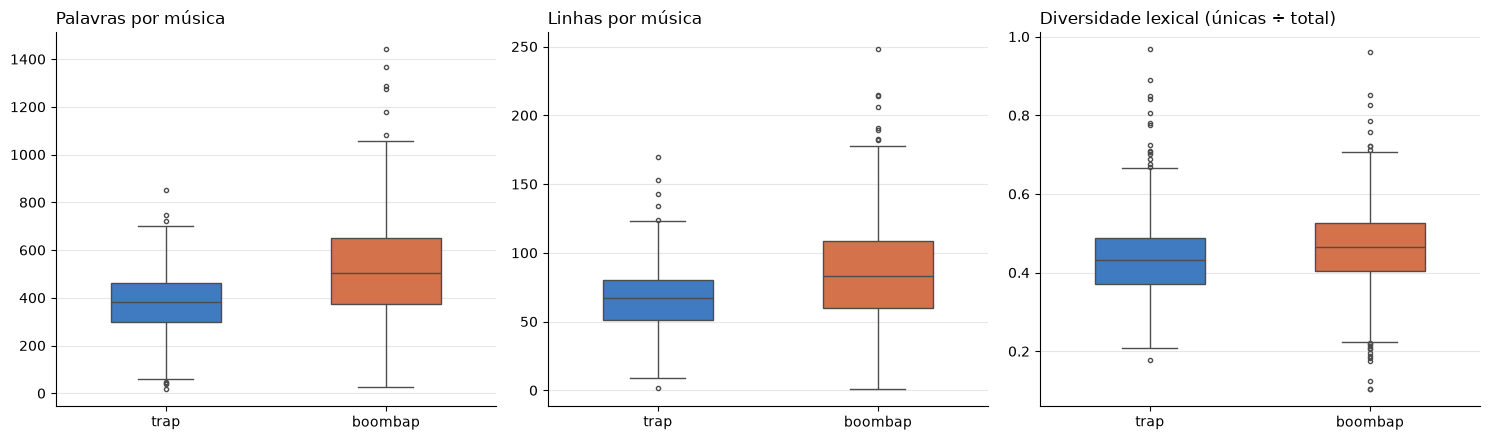

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
graficos = [("palavras", "Palavras por música"),
            ("linhas", "Linhas por música"),
            ("diversidade_lexical", "Diversidade lexical (únicas ÷ total)")]
for ax, (coluna, titulo) in zip(axes, graficos):
    sns.boxplot(data=df, x="genero", y=coluna, hue="genero", palette=CORES,
                width=0.5, linewidth=1, fliersize=3, legend=False, ax=ax)
    ax.set_title(titulo, loc="left")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(axis="y", alpha=0.3)
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 3.3 Músicas por artista

`MAX_POR_ARTISTA` limita o peso de cada artista na base. Artistas com poucas músicas têm poucas letras no LRCLIB ou tiveram faixas descartadas como repetidas.

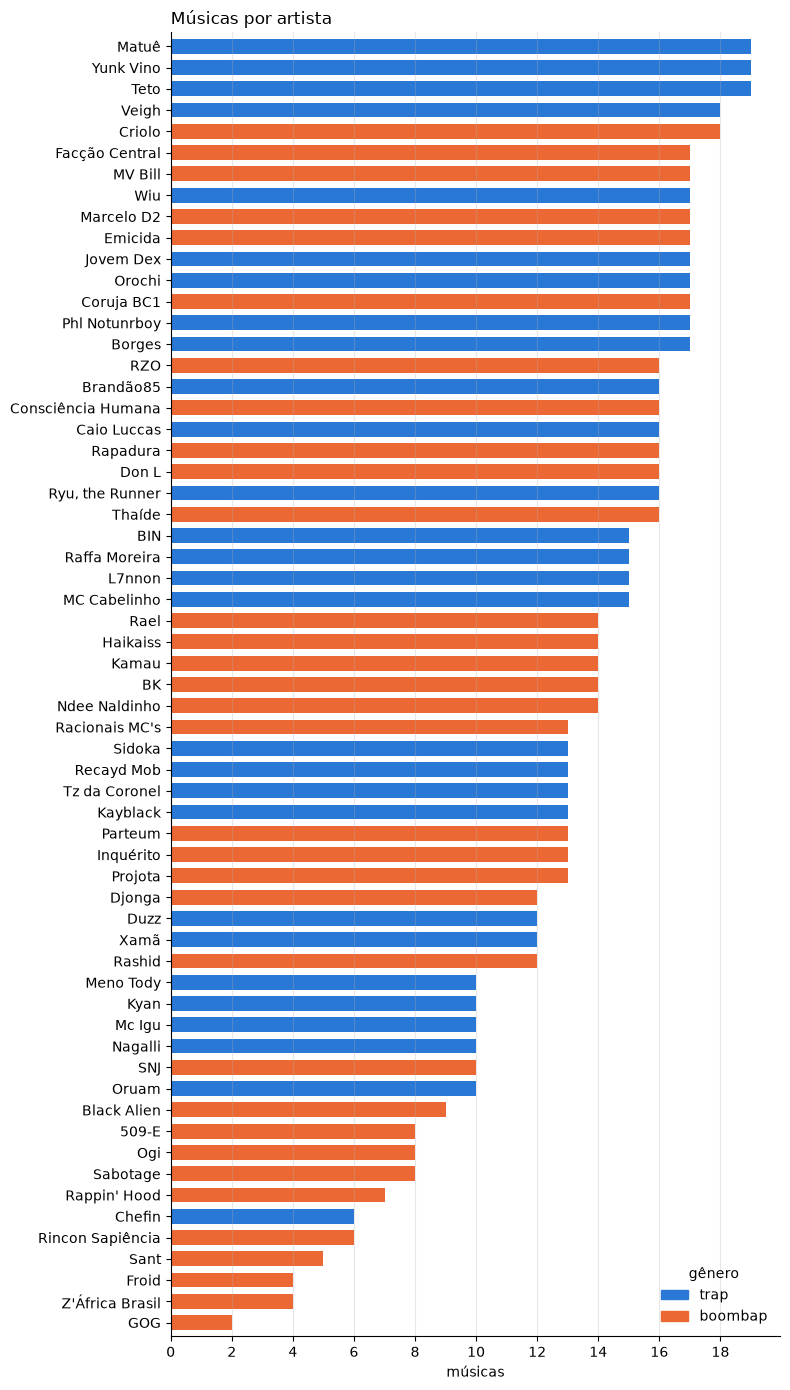

In [6]:
por_artista = (df.groupby(["artista", "genero"]).size()
                 .reset_index(name="musicas").sort_values("musicas"))

fig, ax = plt.subplots(figsize=(8, 14))
ax.barh(por_artista["artista"], por_artista["musicas"],
        color=por_artista["genero"].map(CORES), height=0.7)
ax.legend(handles=[Patch(color=c, label=g) for g, c in CORES.items()],
          title="gênero", loc="lower right", frameon=False)
ax.set_title("Músicas por artista", loc="left")
ax.set_xlabel("músicas")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.margins(y=0.005)
ax.grid(axis="x", alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 3.4 Palavras mais frequentes

Contagem bruta, sem tratamento. Stopwords como "que", "de" e "eu" dominam o topo e dizem pouco sobre o gênero; por isso a seção 4.5 as remove.

In [7]:
top = {}
for genero, grupo in df.groupby("genero"):
    contagem = Counter(w for t in tokens[grupo.index] for w in t)
    print(f"{genero}: vocabulário de {len(contagem)} palavras diferentes")
    top[genero] = [f"{w} ({n})" for w, n in contagem.most_common(20)]
pd.DataFrame(top, index=range(1, 21))

boombap: vocabulário de 18464 palavras diferentes
trap: vocabulário de 11962 palavras diferentes


,boombap,trap
1,que (5831),eu (4727)
2,o (5371),que (3972)
3,a (5115),o (3095)
4,é (4949),de (2973)
5,de (4590),não (2810)
6,e (4318),a (2536)
7,não (4254),é (2504)
8,eu (3697),e (2350)
9,pra (2560),me (1930)
10,se (2352),no (1776)


### 3.5 Problemas de qualidade

A busca no LRCLIB é por nome, e artistas homônimos entram na base: "Teto" trouxe músicas da Kasane Teto (vocaloid japonesa), "Rashid" e "BIN" trouxeram letras em árabe e indonésio, "Sabotage" trouxe Hippie Sabotage.

Para encontrá-los, mede-se a proporção de palavras muito comuns do português em cada letra. Letras em português ficam em torno de 30%; valores muito abaixo disso quase sempre indicam outro idioma ou outro artista. A célula também conta os problemas de formatação que a seção 4.2 corrige.

In [8]:
PT_COMUNS = {"que", "de", "o", "a", "e", "não", "nao", "eu", "é", "do", "da", "pra", "me",
             "um", "na", "no", "se", "com", "você", "tu", "mas", "os", "as", "meu", "minha",
             "tá", "to", "tô", "isso", "quem", "mano"}
LIMITE_PT = 0.08  # heurística: abaixo de 8% de palavras comuns do português, a letra é suspeita

df["proporcao_pt"] = tokens.apply(lambda t: sum(w in PT_COMUNS for w in t) / max(len(t), 1))
suspeitas = df[df["proporcao_pt"] < LIMITE_PT]
print(f"{len(suspeitas)} letras ({len(suspeitas) / len(df):.1%}) quase sem português, por artista:")
display(suspeitas.groupby(["genero", "artista"]).size().sort_values(ascending=False).rename("musicas"))

NUMERO_FAIXA = r"^\d+\.\s"
FEAT = r"\bfeat\.|\bft\."
print(f"Títulos com número de faixa ('3. VEIGH - ...'): {df['titulo'].str.contains(NUMERO_FAIXA).sum()}")
print(f"Títulos com o artista junto ('Matuê - ...'): {df['titulo'].str.contains(' - ').sum()}")
print(f"Títulos com feat./ft.: {df['titulo'].str.contains(FEAT, case=False).sum()}")
print(f"Letras com marcações tipo [Refrão]: {df['letra'].str.contains(r'\[').sum()}")
print(f"Letras muito curtas (< 50 palavras): {(df['palavras'] < 50).sum()}")

48 letras (6.0%) quase sem português, por artista:


genero   artista        
boombap  Rashid             10
trap     Teto               10
         BIN                 9
boombap  Ogi                 6
         BK                  3
         Kamau               2
         Rael                2
         Sabotage            2
trap     Kyan                2
         Matuê               1
         Ryu, the Runner     1
Name: musicas, dtype: int64

Títulos com número de faixa ('3. VEIGH - ...'): 32
Títulos com o artista junto ('Matuê - ...'): 171
Títulos com feat./ft.: 125
Letras com marcações tipo [Refrão]: 6
Letras muito curtas (< 50 palavras): 6


## 4. Tratamento de dados

1. Remoção de músicas que não são dos artistas buscados (homônimos estrangeiros e brasileiros).
2. Limpeza de títulos e letras.
3. Novas variáveis numéricas.
4. Embeddings de título e letra.
5. Novas variáveis por gênero.
6. Agrupamentos.

### 4.1 Remoção de homônimos

A busca por nome traz homônimos: Kasane Teto (vocaloid japonesa), cantores indianos e árabes chamados Rashid, a banda indonésia BIN, rappers turcos e búlgaros chamados Ogi, entre outros. O LRCLIB também tem letras cadastradas na faixa errada: em "Curtir na Moral", do Thaíde, a letra é de uma música da Britney Spears.

**Por que não detectar o idioma da letra inteira:** o rap brasileiro mistura português e inglês e às vezes abre com trechos em outra língua ("Apocalipse 1: 18-19", do Ryu, the Runner, começa com uma citação bíblica em grego). Na letra inteira, o idioma dominante engana.

**Critério:** o idioma é detectado **linha a linha**, e mede-se a proporção de linhas em português. Os homônimos têm 0% de linhas em português; as músicas brasileiras com mais mistura começam em ~27%. O corte em 10% fica no meio desse intervalo. Efeito colateral aceito: músicas de artistas brasileiros cantadas inteiramente em inglês também saem, pois seriam ruído para um modelo de letras em português.

**Homônimos brasileiros:** o filtro de idioma não os detecta. A análise de erros (seção 8) revelou dois casos, removidos por inteiro e retirados da lista de coleta:
- **Rapadura:** 15 das 16 músicas eram da banda de forró *Caviar com Rapadura*;
- **Borges:** a maioria das músicas era de Lô Borges e Márcio Borges (MPB) e de Leandro Borges (gospel), não do Borges do trap.

In [9]:
DetectorFactory.seed = 0  # langdetect é aleatório; a semente torna o resultado reproduzível
MIN_PALAVRAS_LINHA = 4    # linhas curtas ("yeah, yeah") não permitem identificar o idioma
MIN_LINHAS_PT = 0.10      # homônimos: 0% de linhas em português; músicas brasileiras: 27% ou mais


def proporcao_linhas_pt(letra: str) -> float:
    linhas = {l.strip() for l in letra.splitlines() if len(l.split()) >= MIN_PALAVRAS_LINHA}  # refrão conta uma vez
    if not linhas:
        return 0.0
    em_pt = 0
    for linha in linhas:
        try:
            em_pt += detect(linha) == "pt"
        except LangDetectException:
            pass
    return em_pt / len(linhas)


# Homônimos brasileiros, encontrados na análise de erros (o filtro de idioma não os detecta):
# "Rapadura" trouxe a banda de forró Caviar com Rapadura; "Borges" trouxe Lô e Márcio Borges (MPB)
# e Leandro Borges (gospel). Saem inteiros: não há como separar o Borges do trap dos demais.
ARTISTAS_HOMONIMOS = {"Rapadura", "Borges"}

df["linhas_pt"] = df["letra"].apply(proporcao_linhas_pt)  # cerca de 1 minuto
tem_pt = df["linhas_pt"] >= MIN_LINHAS_PT
homonimo = df["artista"].isin(ARTISTAS_HOMONIMOS)
removidas = df[~tem_pt | homonimo]
df_tratado = df.loc[tem_pt & ~homonimo, ["artista", "titulo", "genero", "letra"]].copy()

print(f"{(~tem_pt).sum()} músicas sem português + {(tem_pt & homonimo).sum()} de homônimos brasileiros "
      f"({', '.join(sorted(ARTISTAS_HOMONIMOS))}) = {len(removidas)} removidas")
print(f"{len(df_tratado)} mantidas, de {df_tratado['artista'].nunique()} artistas\n")
print(df_tratado["genero"].value_counts().to_string())
display(removidas.groupby(["genero", "artista"]).size().sort_values(ascending=False).rename("removidas"))

58 músicas sem português + 32 de homônimos brasileiros (Borges, Rapadura) = 90 removidas
710 mantidas, de 58 artistas

genero
trap       359
boombap    351


genero   artista      
trap     Borges           17
boombap  Rapadura         16
         Rashid           11
trap     Teto             11
         BIN               9
boombap  Ogi               8
         BK                5
         Rael              3
         Kamau             2
         Sabotage          2
trap     Kyan              2
boombap  Rappin' Hood      1
         Thaíde            1
trap     Matuê             1
         Raffa Moreira     1
Name: removidas, dtype: int64

In [10]:
# Lista completa das removidas, para conferência (linhas_pt >= 0.10 = homônimo brasileiro)
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 60):
    display(removidas[["genero", "artista", "titulo", "linhas_pt"]].sort_values(["genero", "artista"]))

,genero,artista,titulo,linhas_pt
488,boombap,BK,BK - ICY (Official Music Video),0.029412
490,boombap,BK,BK - KIRPANA (Official Video) Latest Punjabi Songs 2023,0.000000
491,boombap,BK,BK - Aaja Billo (Official Video 4K) New Punjabi Songs 20...,0.000000
498,boombap,BK,College,0.000000
500,boombap,BK,Sunni,0.000000
510,boombap,Kamau,B4 EVERYTHING HAPPENED,0.000000
511,boombap,Kamau,FALLING DOWN,0.000000
744,boombap,Ogi,"OGI X POIZI - SENI BIRŞEY SANDIM (PROD BY. SNOW,BERKAY K...",0.000000
745,boombap,Ogi,Чернова (ft. Дичо),0.000000
746,boombap,Ogi,Това е обир (ft. Geoff Lagadec),0.000000


### 4.2 Limpeza de título e letra

- **Título:** remove o número da faixa ("3. VEIGH - MANDRAKA"), o nome do artista no início e todo trecho entre parênteses ou colchetes ("(feat. ...)", "(Official Video)", "(Deluxe)"), além de "feat."/"ft." soltos.
- **Letra:** remove marcações como `[Refrão]` e `[Verso 1: ...]`, que não fazem parte do que é cantado.

A letra **mantém** stopwords e pontuação: o modelo de embeddings usa o contexto da frase inteira, e remover palavras pioraria a representação. Stopwords só são descartadas na contagem de termos frequentes (seção 4.5).

In [11]:
NUMERO_FAIXA = r"^\d+\.\s*"
ENTRE_PARENTESES = r"\s*[\(\[][^\)\]]*[\)\]]"
FEAT_SOLTO = r"\s*\(?\s*\b(feat|ft)\b\.?.*$"  # também pega "(feat. X" sem fechar
MARCACAO = r"\[[^\]]*\]"                      # [Refrão], [Verso 1: MC ...]
ARTISTAS_CONHECIDOS = [normalizar(a) for lista in ARTISTAS.values() for a in lista]


def comeca_com_artista(trecho: str) -> bool:
    trecho = normalizar(trecho)
    return any(re.search(rf"\b{re.escape(a)}\b", trecho) for a in ARTISTAS_CONHECIDOS)


def limpar_titulo(titulo: str) -> str:
    t = re.sub(NUMERO_FAIXA, "", titulo)
    t = re.sub(ENTRE_PARENTESES, "", t)
    t = re.sub(FEAT_SOLTO, "", t, flags=re.IGNORECASE)
    partes = t.split(" - ")
    if len(partes) > 1 and comeca_com_artista(partes[0]):  # "Matuê - Quer Voar" -> "Quer Voar"
        t = " - ".join(partes[1:])
    return t.strip(" -") or titulo  # se não sobrar nada, mantém o original


df_tratado["titulo_limpo"] = df_tratado["titulo"].apply(limpar_titulo)
df_tratado["letra_limpa"] = df_tratado["letra"].str.replace(MARCACAO, "", regex=True).str.strip()

mudou = df_tratado[df_tratado["titulo"] != df_tratado["titulo_limpo"]]
print(f"{len(mudou)} títulos limpos. Exemplos:")
mudou[["titulo", "titulo_limpo"]].sample(15, random_state=1)

289 títulos limpos. Exemplos:


,titulo,titulo_limpo
282,Kurt Cobain (Acústico),Kurt Cobain
691,Black Alien - Como Eu Te Quero,Como Eu Te Quero
536,Facção Central - Estrada da dor 666,Estrada da dor 666
127,11 - Yunk Vino - Campari (Prod. 808 Luke) [Viz...,11 - Yunk Vino - Campari
221,L7NNON - Da Boca (prod. Papatinho),Da Boca
65,4. VEIGH - Artista Genérico (Eu Venci o Mundo),Artista Genérico
190,Tz da Coronel - Nota Dó ft. Kawe & Vulgo FK (P...,Nota Dó
425,Triunfo (2022),Triunfo
184,Tz da Coronel - Cheiro de Sexo (Prod. meLLo),Cheiro de Sexo
505,Tambor (feat. Rincon Sapiência & Thalma de Fre...,Tambor


### 4.3 Novas variáveis

Por música:
- **qtd_linhas:** linhas não vazias da letra;
- **qtd_palavras:** palavras (apenas letras, sem números);
- **qtd_estrangeiras** e **pct_estrangeiras:** número e proporção de palavras estrangeiras.

**Critério de palavra estrangeira:** o `wordfreq` fornece a frequência de cada palavra em vários idiomas, medida em textos reais, na escala *zipf* (log10; uma unidade = 10× mais frequente). Uma palavra é estrangeira quando é comum em inglês (zipf ≥ 3) e bem mais comum em inglês que em português (diferença ≥ 0,75, isto é, ~5,6×). O critério captura "yeah", "baby", "bitch", "gang", "money" e "drip", e mantém "mano", "vida" e "quebrada" como português.

A comparação é feita só com o inglês, origem de praticamente todos os empréstimos do rap brasileiro; incluir o espanhol fazia gírias como "manos" e "memo" contarem como estrangeiras. Palavras que também existem em português (muitas vezes sem acento) ficam numa lista de exceções: "to" (tô), "for" (se for), "so" (só), "grade", "come", "age".

In [12]:
PALAVRA = r"[^\W\d_]+"  # apenas letras
MIN_ZIPF_EN = 3.0       # a palavra precisa ser comum em inglês
MARGEM_EN = 0.75        # ~5,6x mais comum em inglês que em português
NAO_ESTRANGEIRAS = {  # existem em português (muitas vezes sem acento), gírias e interjeições
    "to", "for", "so", "grade", "come", "age", "memo", "manos", "ha", "ay", "ahn",
}


@functools.lru_cache(maxsize=None)
def estrangeira(palavra: str) -> bool:
    if palavra in NAO_ESTRANGEIRAS:
        return False
    en = zipf_frequency(palavra, "en")
    return en >= MIN_ZIPF_EN and en - zipf_frequency(palavra, "pt") >= MARGEM_EN


palavras = df_tratado["letra_limpa"].str.lower().str.findall(PALAVRA)
df_tratado["qtd_linhas"] = df_tratado["letra_limpa"].apply(lambda t: sum(bool(l.strip()) for l in t.splitlines()))
df_tratado["qtd_palavras"] = palavras.str.len()
df_tratado["qtd_estrangeiras"] = palavras.apply(lambda ps: sum(map(estrangeira, ps)))
df_tratado["pct_estrangeiras"] = df_tratado["qtd_estrangeiras"] / df_tratado["qtd_palavras"]

NOVAS = ["qtd_linhas", "qtd_palavras", "qtd_estrangeiras", "pct_estrangeiras"]
df_tratado.groupby("genero")[NOVAS].describe().T.round(2)

genero                  boombap    trap
qtd_linhas       count   351.00  359.00
                 mean     79.67   58.65
                 std      31.03   18.10
                 min       1.00    2.00
                 25%      58.00   46.00
                 50%      78.00   58.00
                 75%      99.00   69.50
                 max     203.00  137.00
qtd_palavras     count   351.00  359.00
                 mean    546.66  393.48
                 std     212.15  114.27
                 min     104.00   18.00
                 25%     400.00  318.00
                 50%     523.00  389.00
                 75%     658.00  464.00
                 max    1434.00  852.00
qtd_estrangeiras count   351.00  359.00
                 mean      6.02   23.04
                 std      17.90   34.59
                 min       0.00    0.00
                 25%       0.00    4.00
                 50%       2.00   11.00
                 75%       5.00   29.50
                 max     183.00  338.00
pct_estrangeiras count   351.00  359.00
                 mean      0.01    0.06
                 std       0.04    0.08
                 min       0.00    0.00
                 25%       0.00    0.01
                 50%       0.00    0.03
                 75%       0.01    0.07
                 max       0.48    0.67

### 4.4 Embeddings de título e letra

**Modelo:** [`Qwen/Qwen3-Embedding-0.6B`](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B), executado localmente (sem custo e sem chave de API). Motivos da escolha:
- **Letra inteira, sem truncamento.** As letras têm em média ~780 tokens (a maior, ~2.500), e o modelo aceita até 32 mil. Modelos multilíngues populares (`paraphrase-multilingual-*`, `multilingual-e5`) param em 128–512 tokens e leriam apenas o primeiro verso.
- **Multilíngue** (100+ idiomas): português, gírias e o inglês misturado do trap no mesmo espaço vetorial.
- **Qualidade:** no benchmark MMTEB (segundo o model card), média de 64,3 contra 63,2 do `multilingual-e5-large-instruct`, de mesmo porte, e 66,8 contra 64,9 nas tarefas de classificação.
- **Leve:** 0,6 B de parâmetros (~1,2 GB em float16); roda em GPU (CUDA ou Apple MPS) ou, mais devagar, em CPU. Em float16 os vetores ficaram praticamente idênticos aos de float32 (similaridade de cosseno de 0,9998), com inferência mais rápida.

**Decisões de uso:**
- **Título e letra em vetores separados** (1024 dimensões cada): num texto único, as ~5 palavras do título se perderiam entre as ~500 da letra. Separados, o classificador decide o peso de cada um.
- **Instrução de tarefa:** o modelo é treinado com instruções em inglês, e o model card recomenda usá-las (+1 a 5% de qualidade). A instrução descreve o que representar (estilo, vocabulário, temas) **sem mencionar os rótulos**.
- **Vetores normalizados** (norma 1): a similaridade de cosseno equivale ao produto escalar.
- **Cache em `embeddings.npz`:** cada vetor é indexado pelo hash de modelo, instrução e texto, então novas execuções só calculam textos inéditos. O cache é salvo a cada bloco, e uma interrupção não perde trabalho.

In [13]:
MODELO = "Qwen/Qwen3-Embedding-0.6B"
ARQ_EMBEDDINGS = "embeddings.npz"
BLOCO = 64  # salva o cache a cada 64 textos
INSTRUCOES = {
    "letra": "Instruct: Represent the lyrics of this Brazilian hip hop song by its style, vocabulary and themes\nQuery: ",
    "titulo": "Instruct: Represent the title of this Brazilian hip hop song\nQuery: ",
}

try:
    _z = np.load(ARQ_EMBEDDINGS)
    cache = dict(zip(_z["hashes"], _z["vetores"]))
except FileNotFoundError:
    cache = {}
modelo = None


def embeddar(textos: list, tipo: str) -> np.ndarray:
    global modelo
    prompt = INSTRUCOES[tipo]
    hashes = [hashlib.sha1((MODELO + prompt + t).encode()).hexdigest() for t in textos]
    faltando = list({h: t for h, t in zip(hashes, textos) if h not in cache}.items())
    if faltando and modelo is None:  # só carrega o modelo se houver texto novo
        modelo = SentenceTransformer(MODELO, model_kwargs={"dtype": torch.float16})
    for i in range(0, len(faltando), BLOCO):
        bloco = faltando[i:i + BLOCO]
        vetores = modelo.encode([t for _, t in bloco], prompt=prompt, batch_size=8,
                                normalize_embeddings=True)
        cache.update(zip([h for h, _ in bloco], vetores))
        np.savez(ARQ_EMBEDDINGS, hashes=np.array(list(cache)), vetores=np.stack(list(cache.values())))
        print(f"  {tipo}: {min(i + BLOCO, len(faltando))}/{len(faltando)} novos")
    return np.stack([cache[h] for h in hashes]).astype(np.float32)


emb_titulo = embeddar(df_tratado["titulo_limpo"].tolist(), "titulo")
emb_letra = embeddar(df_tratado["letra_limpa"].tolist(), "letra")
print(f"título: {emb_titulo.shape} | letra: {emb_letra.shape}")

título: (710, 1024) | letra: (710, 1024)


### 4.5 Novas variáveis por gênero

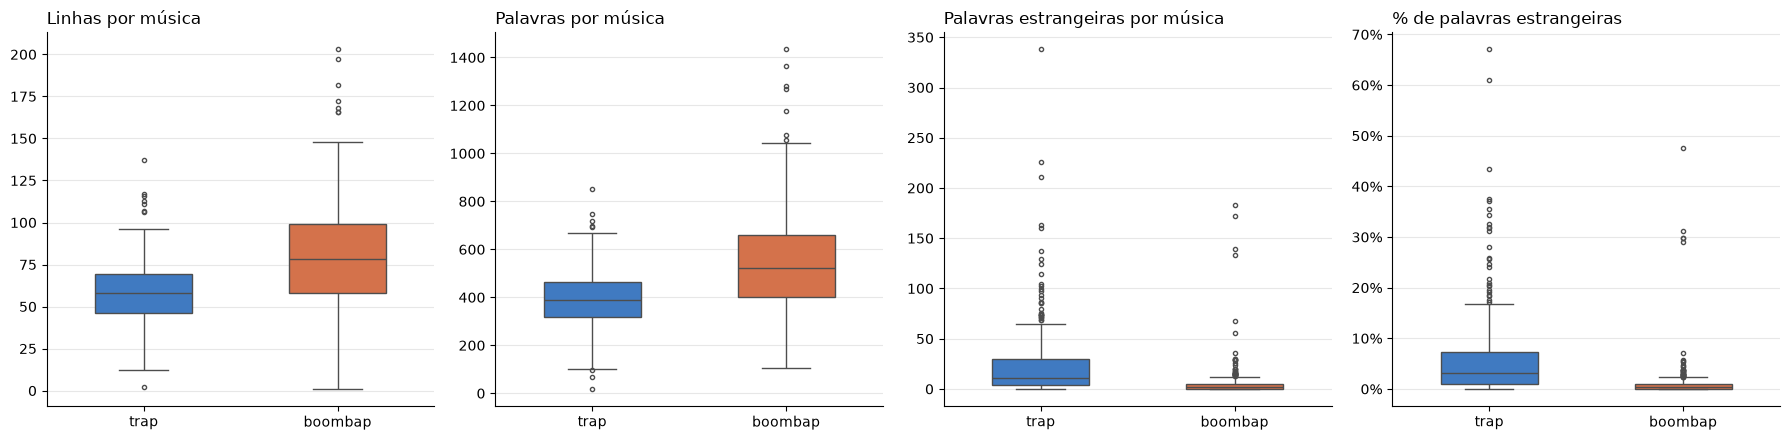

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
graficos = [("qtd_linhas", "Linhas por música"),
            ("qtd_palavras", "Palavras por música"),
            ("qtd_estrangeiras", "Palavras estrangeiras por música"),
            ("pct_estrangeiras", "% de palavras estrangeiras")]
for ax, (coluna, titulo) in zip(axes, graficos):
    sns.boxplot(data=df_tratado, x="genero", y=coluna, hue="genero", palette=CORES,
                width=0.5, linewidth=1, fliersize=3, legend=False, ax=ax)
    ax.set_title(titulo, loc="left")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(axis="y", alpha=0.3)
    sns.despine(ax=ax)
axes[3].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
plt.show()

#### Termos mais frequentes

- **Palavras mais frequentes**, sem stopwords (português e inglês) nem interjeições e verbos muito genéricos ("vai", "vou", "quer", "yeah");
- **Palavras estrangeiras mais frequentes** por gênero;
- **Artistas que mais usam palavras estrangeiras** (% médio por música).

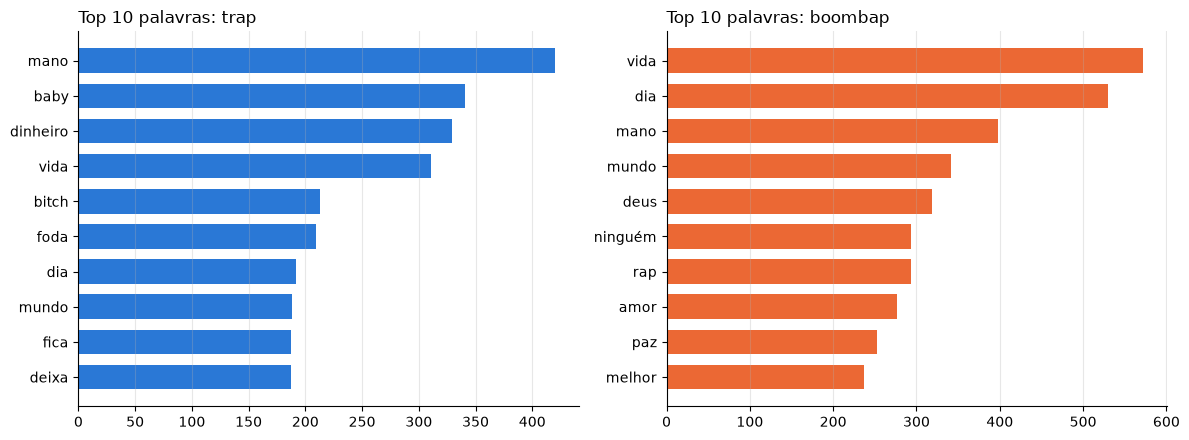

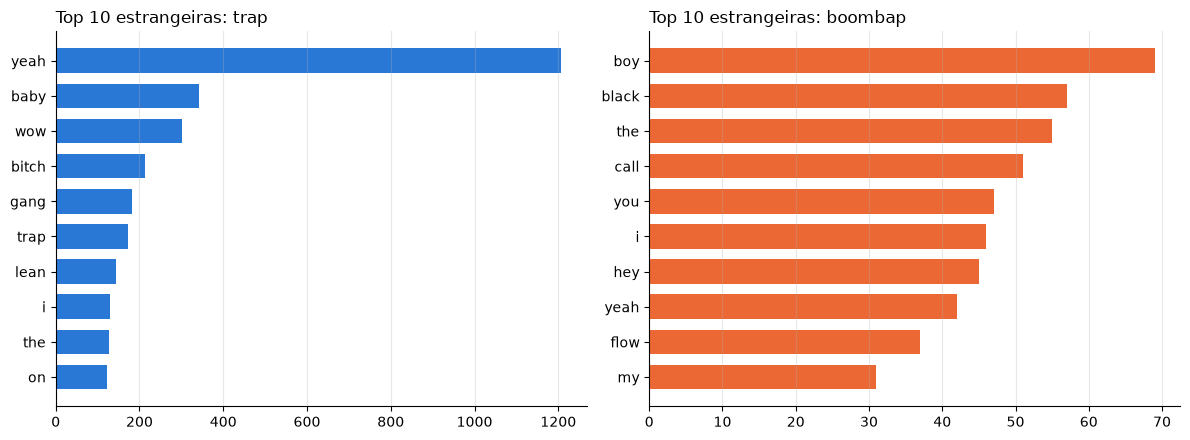

In [15]:
STOPWORDS = set(get_stop_words("portuguese")) | set(ENGLISH_STOP_WORDS) | {
    "vai", "vou", "quer", "quero", "sei", "sabe", "vem", "tão", "pro", "tô", "tá", "cê", "né",
    "ahn", "yeah", "wow", "oh", "ah", "ye", "ay", "hey", "uh", "ooh", "woah", "la", "lá", "ok",
    "tudo", "mim", "nada", "nunca", "sempre", "hoje", "assim", "todo", "toda", "igual", "fala",
    "olha", "ter", "faz", "fazer", "vão", "tem", "ser", "ver", "dá", "sou", "mais", "aqui", "ali",
    "então", "agora", "só", "pode", "posso", "bem", "vez", "nem", "ainda", "cada", "nois", "nóis",
    "nós", "memo", "mesmo", "tipo", "gente", "coisa", "quando", "onde", "porque", "pois",
}


def contar(filtro) -> dict:
    """{gênero: Counter} das palavras que passam no filtro."""
    return {g: Counter(p for ps in palavras[df_tratado["genero"] == g] for p in ps if filtro(p))
            for g in CORES}


def barras_top10(contagens: dict, titulo: str):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, (genero, contagem) in zip(axes, contagens.items()):
        itens = contagem.most_common(10)[::-1]
        ax.barh([p for p, _ in itens], [n for _, n in itens], color=CORES[genero], height=0.7)
        ax.set_title(f"{titulo}: {genero}", loc="left")
        ax.grid(axis="x", alpha=0.3)
        sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()


barras_top10(contar(lambda p: p not in STOPWORDS and len(p) >= 3), "Top 10 palavras")
barras_top10(contar(estrangeira), "Top 10 estrangeiras")

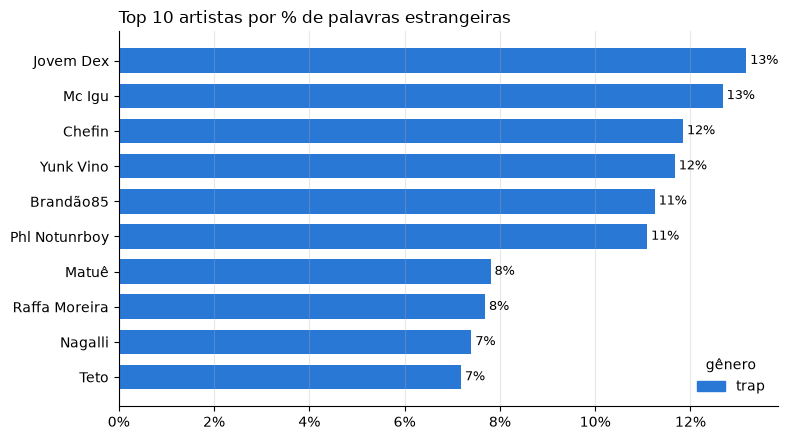

In [16]:
top_artistas = (df_tratado.groupby(["artista", "genero"])["pct_estrangeiras"].mean()
                  .reset_index().nlargest(10, "pct_estrangeiras").iloc[::-1])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top_artistas["artista"], top_artistas["pct_estrangeiras"],
        color=top_artistas["genero"].map(CORES), height=0.7)
for y, v in enumerate(top_artistas["pct_estrangeiras"]):
    ax.text(v, y, f" {v:.0%}", va="center", fontsize=9)
ax.legend(handles=[Patch(color=CORES[g], label=g) for g in top_artistas["genero"].unique()[::-1]],
          title="gênero", loc="lower right", frameon=False)
ax.set_title("Top 10 artistas por % de palavras estrangeiras", loc="left")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 4.6 Agrupamentos

Duas perguntas:
1. **Agrupando as letras sem olhar o rótulo, os grupos coincidem com trap × boom bap?** KMeans com k=2 sobre os embeddings das letras, comparado ao gênero pelo **ARI** (Adjusted Rand Index: 0 = sem relação, 1 = idêntico).
2. **Quão separados estão os gêneros no espaço dos embeddings?** O **silhouette** vai de -1 a 1 (acima de 0, cada música fica mais perto do próprio gênero que do outro). A medida é calculada para letra e título.

Para visualizar os 1024 valores de cada música em 2D, usa-se o **t-SNE**, apenas como visualização: ele preserva vizinhanças, mas distâncias e tamanhos no gráfico não têm significado.

In [17]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42).fit(emb_letra)
df_tratado["cluster"] = [f"cluster {c}" for c in kmeans.labels_]

display(pd.crosstab(df_tratado["cluster"], df_tratado["genero"]))
print(f"ARI (cluster x gênero): {adjusted_rand_score(df_tratado['genero'], df_tratado['cluster']):.2f}")
for nome, emb in [("letra", emb_letra), ("título", emb_titulo)]:
    print(f"silhouette por gênero, {nome}: {silhouette_score(emb, df_tratado['genero'], metric='cosine'):.3f}")

genero,boombap,trap
cluster,,
cluster 0,66,265
cluster 1,285,94


ARI (cluster x gênero): 0.30
silhouette por gênero, letra: 0.055
silhouette por gênero, título: 0.005


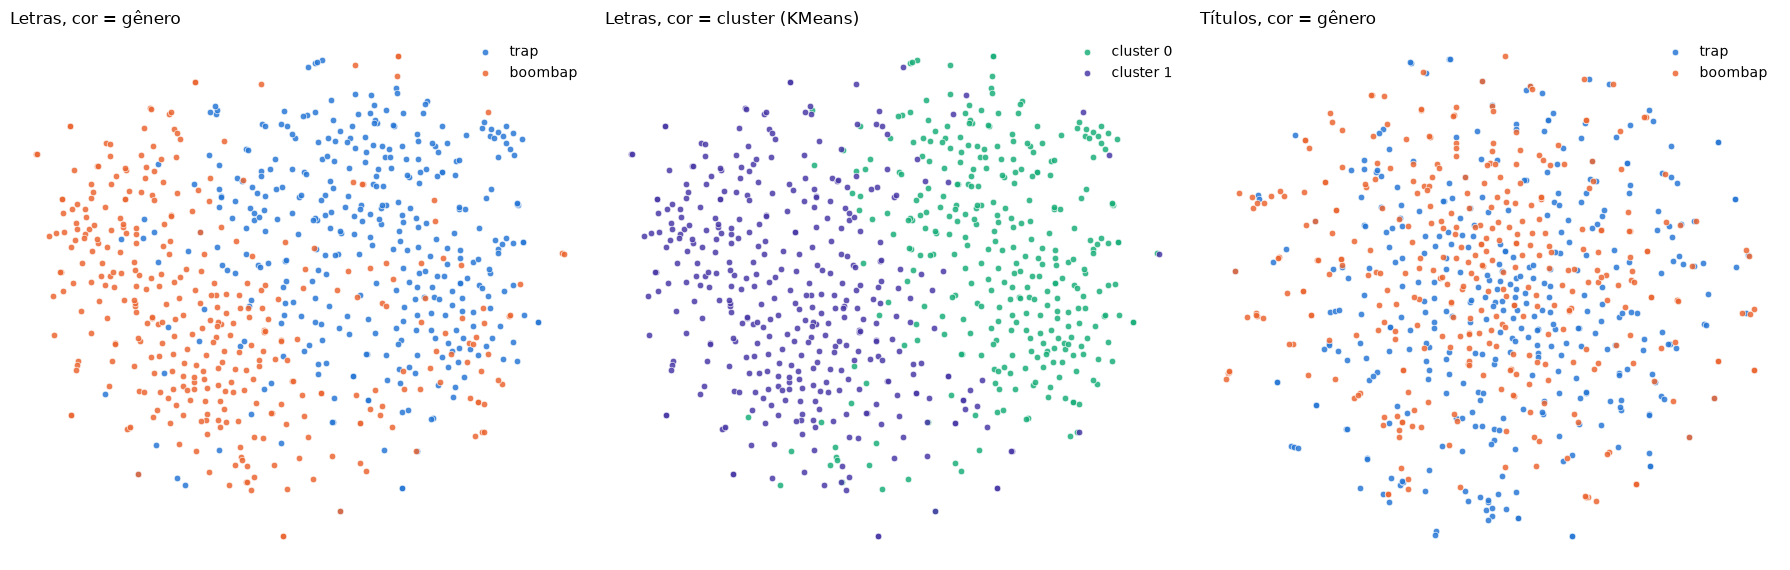

In [18]:
CORES_CLUSTER = {"cluster 0": "#1baf7a", "cluster 1": "#4a3aa7"}  # não repete as cores de gênero

xy_letra = TSNE(n_components=2, metric="cosine", random_state=42).fit_transform(emb_letra)
xy_titulo = TSNE(n_components=2, metric="cosine", random_state=42).fit_transform(emb_titulo)

paineis = [(xy_letra, "genero", CORES, "Letras, cor = gênero"),
           (xy_letra, "cluster", CORES_CLUSTER, "Letras, cor = cluster (KMeans)"),
           (xy_titulo, "genero", CORES, "Títulos, cor = gênero")]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))
for ax, (xy, coluna, cores, titulo) in zip(axes, paineis):
    for grupo, cor in cores.items():
        m = (df_tratado[coluna] == grupo).to_numpy()
        ax.scatter(xy[m, 0], xy[m, 1], s=22, color=cor, label=grupo, alpha=0.85,
                   edgecolors="white", linewidths=0.5)
    ax.set_title(titulo, loc="left")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(frameon=False, loc="best")
    sns.despine(ax=ax, left=True, bottom=True)
plt.tight_layout()
plt.show()

## 5. Separação de treino e teste

**A separação é por artista, não por música.** Com um `train_test_split` comum, músicas do Matuê cairiam no treino e no teste ao mesmo tempo: o modelo aprenderia a reconhecer o *estilo de escrita do Matuê* e acertaria o teste por isso, não por distinguir trap de boom bap. A acurácia sairia inflada e não valeria para artistas novos.

Por isso, `StratifiedGroupKFold`:
- **Group:** cada artista fica inteiro de um só lado;
- **Stratified:** a proporção trap × boom bap se mantém parecida dos dois lados.

A divisão tem dois níveis:
1. **Teste final** (~20% dos artistas): reservado e usado **uma única vez**, na seção 7.
2. **Validação cruzada no treino** (5 partes, também por artista): escolhe a regularização de cada modelo e compara os modelos entre si.

In [19]:
y = df_tratado["genero"].to_numpy()
grupos = df_tratado["artista"].to_numpy()

# uma das 5 partes vira o teste final (~20% dos artistas); as outras 4 formam o treino
divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_treino, idx_teste = next(divisor.split(df_tratado, y, grupos))

artistas_treino, artistas_teste = set(grupos[idx_treino]), set(grupos[idx_teste])
assert not artistas_treino & artistas_teste, "artista vazou entre treino e teste!"

# validação cruzada dentro do treino, também separando por artista
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

treino, teste = df_tratado.iloc[idx_treino], df_tratado.iloc[idx_teste]
display(pd.DataFrame({
    "músicas treino": treino["genero"].value_counts(),
    "músicas teste": teste["genero"].value_counts(),
    "artistas treino": treino.groupby("genero")["artista"].nunique(),
    "artistas teste": teste.groupby("genero")["artista"].nunique(),
}))
for genero in CORES:
    print(f"Artistas de {genero} no teste: {', '.join(sorted(teste.loc[teste['genero'] == genero, 'artista'].unique()))}")

,músicas treino,músicas teste,artistas treino,artistas teste
genero,,,,
boombap,280,71,25,6
trap,289,70,22,5


Artistas de trap no teste: Duzz, Mc Igu, Ryu, the Runner, Sidoka, Yunk Vino
Artistas de boombap no teste: Haikaiss, Kamau, Marcelo D2, RZO, Rappin' Hood, Sabotage


## 6. Modelos

Todos os modelos são **regressões logísticas**; muda apenas **a representação da música**. Assim, a comparação isola o que cada tipo de informação acrescenta:

| modelo | entrada |
|---|---|
| Chute (classe majoritária) | nenhuma: responde sempre a classe mais frequente (piso de referência) |
| Numéricas | `qtd_linhas`, `qtd_palavras`, `qtd_estrangeiras` e `pct_estrangeiras` |
| TF-IDF da letra | palavras e pares de palavras (unigramas e bigramas) |
| Embedding da letra | vetor de 1024 dimensões do Qwen3 |
| Embedding letra + título | os dois vetores concatenados (2048 dimensões) |
| Completo | letra + título + numéricas |

**Prevenção de vazamento:**
- O TF-IDF e o `StandardScaler` ficam **dentro** de um `Pipeline`: em cada rodada da validação cruzada, vocabulário e médias são aprendidos só com a parte de treino.
- Os embeddings dispensam esse cuidado: o Qwen3 foi treinado antes e nunca viu estes dados.
- No modelo completo, apenas as colunas numéricas são padronizadas (variam de 0 a ~1.400); os embeddings já vêm normalizados.

**Regularização (`C`):** há mais variáveis (1024 a 2052) do que músicas de treino (~570), e a regularização é o que impede o modelo de decorar o treino. Cada modelo testa vários valores de `C` na validação cruzada e mantém o melhor.

In [20]:
GRADE_C = [0.01, 0.1, 1, 10, 100, 1000, 10000]


def logistica():
    return LogisticRegression(max_iter=5000)


numericas = df_tratado[NOVAS].to_numpy()  # qtd_linhas, qtd_palavras, qtd_estrangeiras, pct_estrangeiras
X_completo = np.hstack([emb_letra, emb_titulo, numericas])
colunas_numericas = list(range(X_completo.shape[1] - numericas.shape[1], X_completo.shape[1]))

MODELOS = {  # nome: (X, modelo)
    "Chute (classe majoritária)": (numericas, DummyClassifier(strategy="most_frequent")),
    "Numéricas": (numericas, make_pipeline(StandardScaler(), logistica())),
    "TF-IDF da letra": (df_tratado["letra_limpa"].to_numpy(),
                        make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 2)),
                                      logistica())),
    "Embedding da letra": (emb_letra, logistica()),
    "Embedding letra + título": (np.hstack([emb_letra, emb_titulo]), logistica()),
    "Completo": (X_completo, make_pipeline(
        ColumnTransformer([("num", StandardScaler(), colunas_numericas)], remainder="passthrough"),
        logistica())),
}

resultados, ajustados = [], {}
for nome, (X, modelo) in MODELOS.items():
    param_c = [p for p in modelo.get_params() if p == "C" or p.endswith("__C")]  # o chute não tem C
    grade = {param_c[0]: GRADE_C} if param_c else {}
    busca = GridSearchCV(modelo, grade, cv=cv, scoring="accuracy", n_jobs=-1)
    busca.fit(X[idx_treino], y[idx_treino], groups=grupos[idx_treino])
    ajustados[nome] = busca.best_estimator_  # já retreinado com o treino inteiro
    i = busca.best_index_
    resultados.append({"modelo": nome,
                       "C": busca.best_params_.get(param_c[0]) if param_c else None,
                       "acurácia CV": busca.cv_results_["mean_test_score"][i],
                       "desvio CV": busca.cv_results_["std_test_score"][i]})
    print(f"{nome}: {resultados[-1]['acurácia CV']:.3f} ± {resultados[-1]['desvio CV']:.3f}")

tabela = pd.DataFrame(resultados).set_index("modelo")

Chute (classe majoritária): 0.508 ± 0.013


Numéricas: 0.735 ± 0.024


TF-IDF da letra: 0.919 ± 0.041


Embedding da letra: 0.859 ± 0.070


Embedding letra + título: 0.839 ± 0.066


Completo: 0.868 ± 0.041


## 7. Avaliação

Duas medidas por modelo:
- **Acurácia na validação cruzada** (média ± desvio das 5 partes do treino): critério de **escolha** do modelo.
- **Acurácia e F1 no teste final:** artistas que nenhum modelo viu; é a estimativa honesta para artistas novos.

O teste tem apenas 11 artistas (141 músicas): um artista difícil a mais ou a menos move vários pontos percentuais. Por isso a escolha usa a validação cruzada; escolher pelo teste seria ajustar o modelo à prova.

In [21]:
for nome, (X, _) in MODELOS.items():
    previsto = ajustados[nome].predict(X[idx_teste])
    tabela.loc[nome, "acurácia teste"] = accuracy_score(y[idx_teste], previsto)
    tabela.loc[nome, "F1 macro teste"] = f1_score(y[idx_teste], previsto, average="macro")

escolhido = tabela["acurácia CV"].idxmax()
print(f"Melhor modelo pela validação cruzada: {escolhido}")
tabela.round(3)

Melhor modelo pela validação cruzada: TF-IDF da letra


,C,acurácia CV,desvio CV,acurácia teste,F1 macro teste
modelo,,,,,
Chute (classe majoritária),NaN,0.508,0.013,0.496,0.332
Numéricas,1.0,0.735,0.024,0.809,0.808
TF-IDF da letra,1000.0,0.919,0.041,0.936,0.936
Embedding da letra,100.0,0.859,0.070,0.901,0.900
Embedding letra + título,10.0,0.839,0.066,0.887,0.886
Completo,1000.0,0.868,0.041,0.872,0.872


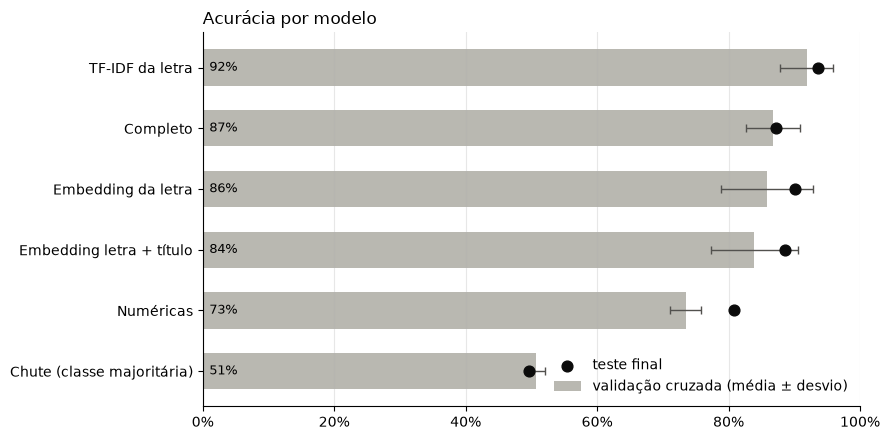

In [22]:
ordem = tabela.sort_values("acurácia CV")
pos = np.arange(len(ordem))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(pos, ordem["acurácia CV"], xerr=ordem["desvio CV"], height=0.6, color="#b9b8b1",
        error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 3}, label="validação cruzada (média ± desvio)")
ax.scatter(ordem["acurácia teste"], pos, s=60, color="#0b0b0b", zorder=3, label="teste final")
for y_pos, v in zip(pos, ordem["acurácia CV"]):
    ax.text(0.01, y_pos, f"{v:.0%}", va="center", fontsize=9)
ax.set_yticks(pos, ordem.index)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Acurácia por modelo", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

In [23]:
X_escolhido, _ = MODELOS[escolhido]
previsto = ajustados[escolhido].predict(X_escolhido[idx_teste])

print(f"{escolhido}, no teste final:\n")
print(classification_report(y[idx_teste], previsto, digits=3))
matriz = pd.crosstab(pd.Series(y[idx_teste], name="real"), pd.Series(previsto, name="previsto"))
display(matriz)

TF-IDF da letra, no teste final:

              precision    recall  f1-score   support

     boombap      0.931     0.944     0.937        71
        trap      0.942     0.929     0.935        70

    accuracy                          0.936       141
   macro avg      0.936     0.936     0.936       141
weighted avg      0.936     0.936     0.936       141



previsto,boombap,trap
real,,
boombap,67,4
trap,5,65


## 8. Análise de erros

O teste final tem poucas músicas para uma análise de erros. Aqui, cada música da base recebe a previsão **de um modelo que nunca viu o seu artista** (`cross_val_predict` com 5 partes por artista), usando o modelo escolhido na seção 7 com o mesmo `C`.

Perguntas:
1. Algum artista é errado quase sempre? Nesse caso, o problema pode estar no **rótulo** (herdado do artista, e há artistas que transitam entre os gêneros), não no modelo.
2. Em quais músicas o modelo errou com mais confiança?
3. As músicas erradas têm algo em comum (tamanho, uso de inglês)?
4. Quais termos mais pesam para cada gênero (os pesos do TF-IDF são interpretáveis)?

In [24]:
cv_todas = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
proba = cross_val_predict(clone(ajustados[escolhido]), X_escolhido, y, groups=grupos,
                          cv=cv_todas, method="predict_proba")
col_trap = list(ajustados[escolhido].classes_).index("trap")

erros = df_tratado[["artista", "titulo_limpo", "genero", "qtd_palavras", "pct_estrangeiras"]].copy()
erros["prob_trap"] = proba[:, col_trap]
erros["previsto"] = np.where(erros["prob_trap"] >= 0.5, "trap", "boombap")
erros["acertou"] = erros["previsto"] == erros["genero"]
erros["certeza_no_erro"] = np.where(erros["genero"] == "trap", 1 - erros["prob_trap"], erros["prob_trap"])

print(f"Acurácia com artistas nunca vistos (todas as {len(erros)} músicas): {erros['acertou'].mean():.1%}")
print(erros.groupby("genero")["acertou"].mean().map("{:.1%}".format).to_string())

Acurácia com artistas nunca vistos (todas as 710 músicas): 92.8%
genero
boombap    92.3%
trap       93.3%


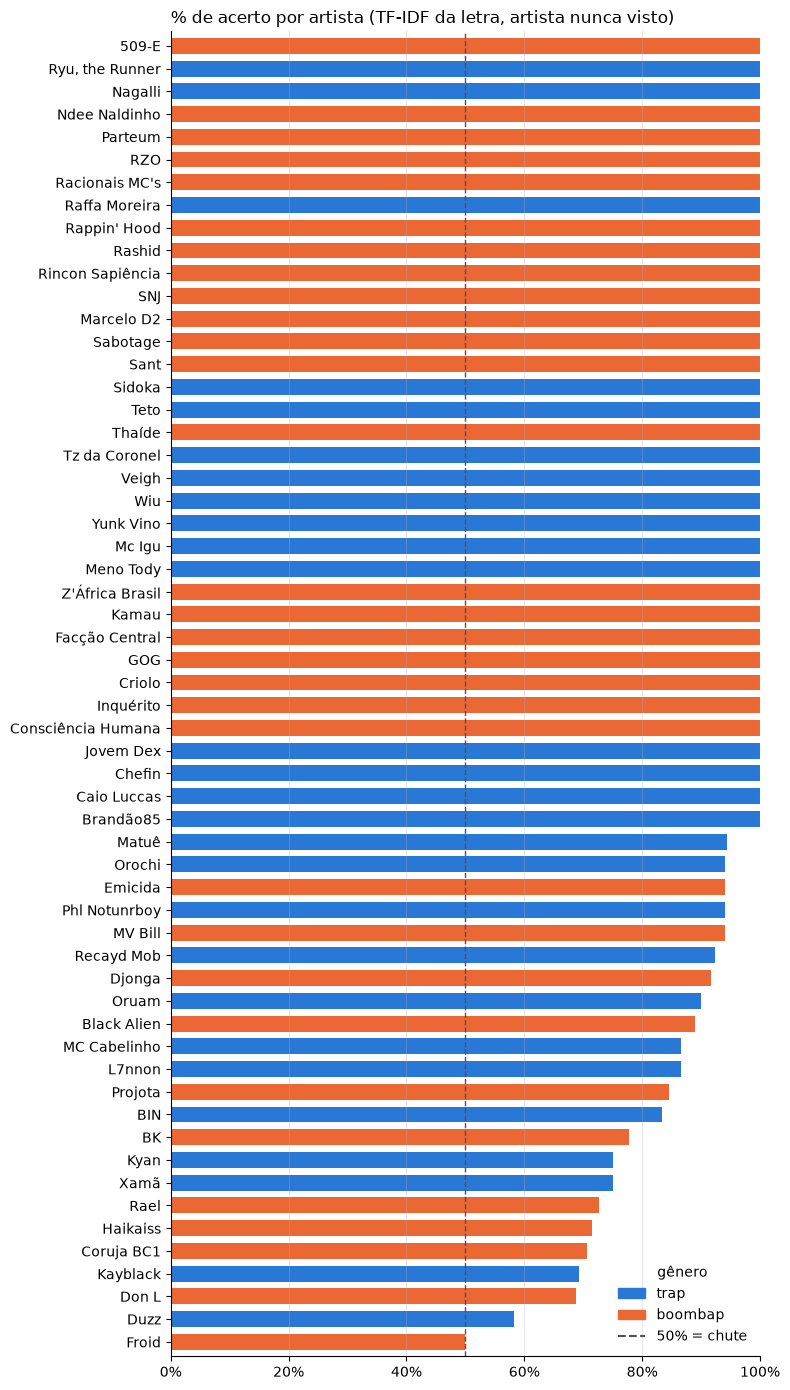

Artistas com menos de 50% de acerto: 0
Artistas com menos de 60% de acerto:


,artista,genero,% acerto,músicas
12,Duzz,trap,0.58,12
15,Froid,boombap,0.50,4


In [25]:
DIFICEIS = 0.6  # artistas com acerto abaixo disso são listados abaixo do gráfico

por_artista = (erros.groupby(["artista", "genero"])["acertou"].agg(["mean", "size"])
                     .reset_index().sort_values("mean", ascending=False))

fig, ax = plt.subplots(figsize=(8, 14))
ax.barh(por_artista["artista"], por_artista["mean"], color=por_artista["genero"].map(CORES), height=0.7)
ax.axvline(0.5, color="#52514e", linewidth=1, linestyle="--")
ax.legend(handles=[Patch(color=c, label=g) for g, c in CORES.items()]
                 + [Line2D([], [], color="#52514e", linestyle="--", label="50% = chute")],
          title="gênero", loc="lower right", frameon=False)
ax.set_title(f"% de acerto por artista ({escolhido}, artista nunca visto)", loc="left")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlim(0, 1)
ax.margins(y=0.005)
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

print(f"Artistas com menos de 50% de acerto: {(por_artista['mean'] < 0.5).sum()}")
print(f"Artistas com menos de {DIFICEIS:.0%} de acerto:")
display(por_artista[por_artista["mean"] < DIFICEIS]
        .rename(columns={"mean": "% acerto", "size": "músicas"}).round(2))

In [26]:
print("Erros com mais certeza (o modelo tinha convicção e errou):")
display(erros[~erros["acertou"]].nlargest(15, "certeza_no_erro")
        [["artista", "titulo_limpo", "genero", "previsto", "certeza_no_erro", "pct_estrangeiras"]].round(2))

print("Mediana das variáveis, por gênero real e acerto:")
erros.groupby(["genero", "acertou"])[["qtd_palavras", "pct_estrangeiras"]].median().round(3)

Erros com mais certeza (o modelo tinha convicção e errou):


,artista,titulo_limpo,genero,previsto,certeza_no_erro,pct_estrangeiras
654,Coruja BC1,Dopamina,boombap,trap,0.98,0.00
101,Kayblack,Intro,trap,boombap,0.98,0.01
721,Haikaiss,Não Sou de Ninguém,boombap,trap,0.97,0.02
102,Kayblack,Maldito Papel,trap,boombap,0.97,0.03
495,BK,Só me ligar,boombap,trap,0.96,0.04
223,L7nnon,Celebrando a Vida - L7NNON Part. John | Podium,trap,boombap,0.93,0.00
230,L7nnon,FAÇA VALER,trap,boombap,0.93,0.00
100,Kayblack,Eu Sei Bem,trap,boombap,0.91,0.00
270,Xamã,BELCHIOR,trap,boombap,0.91,0.08
665,Coruja BC1,Versão Brasileira,boombap,trap,0.90,0.02


Mediana das variáveis, por gênero real e acerto:


qtd_palavras  pct_estrangeiras
genero  acertou                                
boombap False           458.0             0.011
        True            529.5             0.003
trap    False           405.0             0.010
        True            389.0             0.035

trap: yeah, ahn, tu, uh, ela, baby, yeah yeah, tô, bitch, ah, nego, eu tô, wow, nós, gang
boombap: rap, os, sangue, sem, irmão, dos, aqui, pode, ao, por, rua, gente, ou, pois, aí


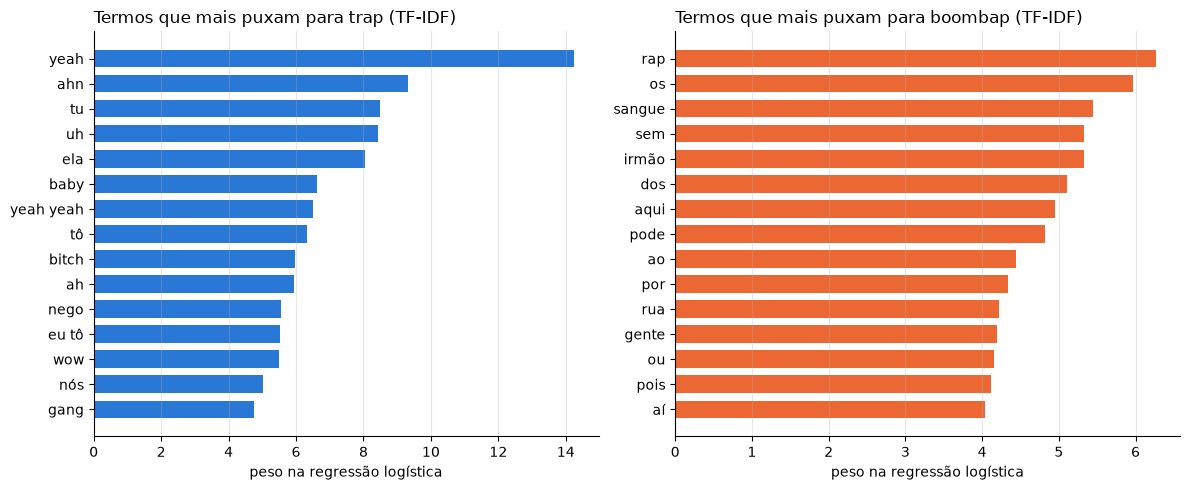

In [27]:
tfidf = ajustados["TF-IDF da letra"]
vocab = tfidf.named_steps["tfidfvectorizer"].get_feature_names_out()
pesos = pd.Series(tfidf.named_steps["logisticregression"].coef_[0], index=vocab)  # positivo = classes_[1]
lado_positivo = tfidf.classes_[1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, genero in zip(axes, CORES):
    top = (pesos if genero == lado_positivo else -pesos).nlargest(15)[::-1]
    print(f"{genero}: {', '.join(top.index[::-1])}")
    ax.barh(top.index, top.values, color=CORES[genero], height=0.7)
    ax.set_title(f"Termos que mais puxam para {genero} (TF-IDF)", loc="left")
    ax.set_xlabel("peso na regressão logística")
    ax.grid(axis="x", alpha=0.3)
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()

## 9. Conclusão

*Números desta execução (sementes fixas, `random_state=42` na divisão), já sem os homônimos: 710 músicas de 58 artistas, 359 de trap e 351 de boom bap.*

### Comparação dos modelos

| modelo | acurácia CV (treino) | acurácia teste |
|---|---|---|
| Chute (classe majoritária) | 50,8% | 49,6% |
| Numéricas | 73,5% ± 2,4 | 80,9% |
| **TF-IDF da letra** | **91,9% ± 4,1** | **93,6%** |
| Embedding da letra | 85,9% ± 7,0 | 90,1% |
| Embedding letra + título | 83,9% ± 6,6 | 88,7% |
| Completo | 86,8% ± 4,1 | 87,2% |

- **O TF-IDF, a representação mais clássica, superou os embeddings** na validação cruzada e no teste. A diferença entre trap e boom bap está sobretudo no **vocabulário e na forma** (interjeições, gírias, inglês, conectivos), que o TF-IDF captura palavra a palavra. O embedding resume o **significado**, e os dois gêneros tratam de temas parecidos (vida, mundo, dinheiro, mano), então parte do sinal de estilo se perde.
- **Os embeddings ainda são competitivos:** 85,9% na validação cruzada sem nenhuma engenharia de texto, porém com maior variação entre as partes (± 7,0).
- **Quatro variáveis numéricas** (tamanho da letra e uso de inglês) já atingem 73,5% na validação cruzada e 80,9% no teste.
- **O título não ajuda:** acrescentar o embedding do título piorou levemente o modelo. O título quase não carrega sinal de gênero (silhouette de 0,005 na seção 4.6) e dobra o número de variáveis.
- **As variáveis numéricas não complementam o embedding** (o modelo "Completo" ficou no mesmo patamar): o embedding já codifica tamanho e uso de inglês.
- **Nesta divisão, o teste ficou acima da validação cruzada:** os 11 artistas sorteados para o teste foram mais fáceis que a média. Com um teste pequeno (141 músicas), isso é esperado, e por isso a escolha do modelo usa a validação cruzada.

### A limpeza de dados rendeu mais que a troca de modelo

Remover os homônimos Borges e Rapadura (32 músicas com rótulo errado) elevou a acurácia do TF-IDF em artistas nunca vistos, medida em todas as músicas, de **89,5% para 92,8%**. Os dois casos foram encontrados na análise de erros: o modelo "errava" justamente as músicas que não eram rap. Depois da limpeza, **nenhum artista fica abaixo de 50% de acerto**.

### O que diferencia os gêneros (pesos do TF-IDF)

- **Trap:** ad-libs e interjeições ("yeah", "ahn", "uh", "ah", "wow"), "tô"/"eu tô", "tu", "ela", "baby", "bitch", "nego", "gang". Letras mais curtas e com mais inglês.
- **Boom bap:** "rap" (metalinguagem: o rap que fala do próprio rap), "sangue", "irmão", "rua", "gente" e muitos conectivos ("os", "dos", "sem", "por", "pois", "ou"), sinal de letras mais longas e narrativas.

### Onde o modelo ainda erra

Os erros restantes se concentram em artistas que **transitam entre os gêneros**:
- **Froid** (50% de acerto) e **Duzz** (58%);
- trap de letra narrativa, como **Kayblack** ("Intro", "Maldito Papel") e **L7nnon** ("FAÇA VALER"), classificado como boom bap;
- rap da nova escola, como **Haikaiss**, **Coruja BC1** e **BK**, classificado como trap;
- **Projota**, em "Rescue Me" (48% de palavras em inglês), classificado como trap.

Nesses casos, o problema está mais no **rótulo por artista** do que no modelo: música a música, esses artistas transitam entre os dois estilos.

### Limitações

- **O rótulo vem do artista**, não da música.
- **O teste é pequeno** (11 artistas, 141 músicas): um artista a mais ou a menos muda vários pontos percentuais, e outra semente produziria outra divisão.
- **A coleta ainda pode trazer homônimos:** a regra aceita o nome buscado como palavra solta dentro do nome de outro artista. Borges e Rapadura foram identificados e removidos, mas um artista novo na lista pode reintroduzir o problema.
- **A fonte tem erros de cadastro**, como a letra da Britney Spears atribuída ao Thaíde.

### Próximos passos

1. **Coleta mais rígida:** exigir que o artista buscado esteja entre os artistas creditados, não apenas como palavra solta no nome.
2. **Combinar TF-IDF e embedding**, e testar TF-IDF de caracteres (captura grafias como "tô", "cê", "nóis").
3. **Mais artistas por gênero**, para um teste final maior e mais estável.

## 10. Classificando uma música nova

Duas funções expõem o modelo vencedor (TF-IDF da letra):
- `classificar_letra(letra)`: recebe o texto da letra;
- `classificar_musica(artista, titulo)`: busca a letra no LRCLIB e a classifica.

Ambas mostram o gênero previsto, a probabilidade e os termos da letra que mais pesaram para cada lado.

**Modelo final:** concluída a avaliação, o TF-IDF é retreinado com **todas** as músicas, mantendo o `C` escolhido na validação cruzada.

**Probabilidades calibradas:** com `C=1000`, a regressão logística é pouco regularizada e superconfiante, atribuindo ~100% a quase toda letra. O `CalibratedClassifierCV` ajusta as probabilidades pelo desempenho em **artistas não vistos** (as mesmas 5 partes por artista). Assim, "80% trap" passa a significar que o modelo acerta cerca de 8 em cada 10 músicas classificadas com essa confiança.

**Avisos automáticos:**
- se a letra já está na base, o modelo a viu no treino e o acerto não comprova nada;
- se a letra tem pouco português, o resultado não é confiável (o modelo conhece apenas rap em português).

In [28]:
letras_treino = df_tratado["letra_limpa"].to_numpy()
tfidf_escolhido = ajustados["TF-IDF da letra"]

# probabilidade: 5 modelos, cada um calibrado em artistas que ele não viu
modelo_final = CalibratedClassifierCV(clone(tfidf_escolhido), method="sigmoid",
                                      cv=list(cv_todas.split(letras_treino, y, grupos)))
modelo_final.fit(letras_treino, y)

# explicação: um TF-IDF treinado com todas as músicas, para ler o peso de cada termo
explicador = clone(tfidf_escolhido).fit(letras_treino, y)
vetorizador_final = explicador.named_steps["tfidfvectorizer"]
pesos_finais = explicador.named_steps["logisticregression"].coef_[0]  # positivo = classes_[1]
termos_finais = vetorizador_final.get_feature_names_out()
letras_no_treino = {normalizar(l)[:200] for l in letras_treino}


def classificar_letra(letra: str, n_palavras: int = 8) -> str:
    """Classifica uma letra como trap ou boombap e mostra os termos que mais pesaram."""
    letra = re.sub(MARCACAO, "", letra).strip()
    if not letra:
        raise ValueError("a letra está vazia")

    proba = dict(zip(modelo_final.classes_, modelo_final.predict_proba([letra])[0]))
    genero = max(proba, key=proba.get)
    print(f"→ {genero.upper()} ({proba[genero]:.0%}) | trap {proba['trap']:.0%} · boombap {proba['boombap']:.0%}")

    if normalizar(letra)[:200] in letras_no_treino:
        print("  ⚠️ esta música está na base: o modelo já a viu no treino, então não é uma previsão real")
    if proporcao_linhas_pt(letra) < MIN_LINHAS_PT:
        print("  ⚠️ a letra tem pouco português: o modelo foi treinado só com rap em português")

    # contribuição de cada termo = valor no TF-IDF desta letra x peso aprendido pelo modelo
    contrib = vetorizador_final.transform([letra]).multiply(pesos_finais).tocsr()
    ordem = contrib.data.argsort()
    lado_positivo, lado_negativo = explicador.classes_[1], explicador.classes_[0]
    pro_positivo = [termos_finais[contrib.indices[i]] for i in ordem[::-1][:n_palavras] if contrib.data[i] > 0]
    pro_negativo = [termos_finais[contrib.indices[i]] for i in ordem[:n_palavras] if contrib.data[i] < 0]
    print(f"  puxaram para {lado_positivo}: {', '.join(pro_positivo) or '-'}")
    print(f"  puxaram para {lado_negativo}: {', '.join(pro_negativo) or '-'}")
    return genero


def buscar_letra(artista: str, titulo: str):
    """(nome encontrado, letra) no LRCLIB, ou None. Só aceita resultados do artista pedido."""
    padrao = re.compile(rf"\b{re.escape(normalizar(artista))}\b")
    nome = f"{artista} - {titulo}"
    resultados = (buscar_artista(nome, params={"artist_name": artista, "track_name": titulo})
                  or buscar_artista(nome, params={"q": f"{artista} {titulo}"}))  # aproximada: acento, "feat." etc.
    for item in resultados:
        if item.get("plainLyrics") and padrao.search(normalizar(item.get("artistName") or "")):
            return f"{item['artistName']} - {item['trackName']}", item["plainLyrics"]
    return None


def classificar_musica(artista: str, titulo: str):
    """Busca a letra no LRCLIB e a classifica. Devolve o gênero, ou None se a letra não for encontrada."""
    achada = buscar_letra(artista, titulo)
    if achada is None:
        print(f"Letra de '{artista} - {titulo}' não encontrada no LRCLIB.")
        return None
    nome, letra = achada
    print(f"🎵 {nome}")
    return classificar_letra(letra)

### Exemplos

Três músicas de artistas **fora da base**, uma música **da base** (para exibir o aviso) e uma letra escrita para o exemplo.

In [29]:
for artista, titulo in [("Filipe Ret", "Neurótico de Guerra"),
                        ("LEALL", "Medo de Quase Nada"),
                        ("Baco Exu do Blues", "Te Amo Disgraça"),
                        ("Racionais MC's", "Fórmula Mágica da Paz")]:  # esta está na base
    classificar_musica(artista, titulo)
    print()

classificar_letra("""
Yeah, yeah, ahn
Acordei tarde, o drip tá no pescoço
Ela me liga, baby, hoje eu tô no corre
Gang no carro, o som no talo, tô de lean
Money na mão, bitch, ninguém mais segura a gente
""");

🎵 Filipe Ret - Neurótico de Guerra
→ BOOMBAP (92%) | trap 8% · boombap 92%
  puxaram para trap: tô, tô no, fumando, eu, falam, fumo, linda, curar
  puxaram para boombap: pode, não pode, rap, ou, irmão, mundo, quem, guerra



🎵 LEALL - Medo de Quase Nada
→ BOOMBAP (51%) | trap 49% · boombap 51%
  puxaram para trap: yeah, tô, eu tô, hoje, eu, nego, hoje eu, ela
  puxaram para boombap: homem, quase nada, medo, olho, cada, fora, saber, rua



🎵 BACO EXU DO BLUES - Te Amo Disgraça
→ TRAP (67%) | trap 67% · boombap 33%


  puxaram para trap: senta, amo, te, ela, eu sou, eu, minha, na minha
  puxaram para boombap: ou, por, morte, desgraça, bar, pois, mulher, vai



🎵 Racionais MC’s - Fórmula mágica da paz
→ BOOMBAP (100%) | trap 0% · boombap 100%
  ⚠️ esta música está na base: o modelo já a viu no treino, então não é uma previsão real


  puxaram para trap: tô, eu tô, eu, minha, eu sou, tá, mano, mas eu
  puxaram para boombap: aí, sangue, aqui, ladrão, os, lei, sem, paz

→ TRAP (100%) | trap 100% · boombap 0%
  puxaram para trap: yeah, ahn, tô, yeah yeah, baby, bitch, gang, lean
  puxaram para boombap: gente, mão, som, ninguém, acordei, na mão, liga, segura
